# 02 · Bowling Action Analysis

Load a video, pull out frames, find body landmarks with MediaPipe, and turn them into joint angles and movement indicators.

Needs: numpy, matplotlib, opencv-python-headless, mediapipe (`pip install -r notebooks/requirements.txt`).

> Running in Google Colab? Run this once in a new cell first (replace the URL with wherever your copy of the project lives), then run the notebook from the top:
> ```python
> !git clone https://github.com/YOUR-ACCOUNT/pitchvision.git   # or upload and unzip the project folder
> %cd pitchvision
> !pip install -q -r notebooks/requirements.txt
> ```

> About the data. The CSV files in `notebooks/data/` are synthetic: generated by `pitchvision/sample_data.py` with a fixed random seed. The players, matches and numbers are invented so the notebook can run straight away. They are not a real team's results. To use your own data, replace the CSV files with files that have the same columns (see `notebooks/data/DATA_DICTIONARY.md`).

In [1]:
# --- Setup: find the project folder so the shared `pitchvision` package can be imported ---
import sys
from pathlib import Path

ROOT = Path.cwd()
if not (ROOT / "pitchvision").exists():        # the notebook is being run from notebooks/
    ROOT = ROOT.parent
if not (ROOT / "pitchvision").exists():
    raise RuntimeError("Cannot find the 'pitchvision' folder. Open this notebook from inside the PitchVision "
                       "project, or see the Google Colab instructions in notebooks/README.md.")
sys.path.insert(0, str(ROOT))

DATA = ROOT / "notebooks" / "data"             # sample CSV files (SYNTHETIC data)
EXPORTS = ROOT / "notebooks" / "exports"       # CSV files written by the notebooks
EXPORTS.mkdir(exist_ok=True)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

plt.rcParams.update({"figure.figsize": (9, 4.5), "axes.grid": True, "grid.alpha": 0.25,
                     "axes.spines.top": False, "axes.spines.right": False, "font.size": 11})
INK, GREEN, RED, YELLOW = "#0D1310", "#1F6B45", "#B3261E", "#F2C230"
print("Project folder:", ROOT)

Project folder: /Users/sahasreddy/Documents/Cricket


## 1. What pose estimation can and cannot tell you

MediaPipe Pose finds 33 body landmarks (shoulders, elbows, hips, knees, ankles...) in each frame. From them we can measure 2-D angles as the camera sees them.

It cannot diagnose an injury, say whether an action is medically safe, or decide whether a bowling action is legal. Testing elbow extension needs calibrated 3-D motion capture in an accredited laboratory. Angles here change with the camera position, so only compare clips filmed from the same spot.

## 2. Use your own video

Put a clip in the project folder and set `VIDEO_PATH` below (in Colab, upload it with the file browser on the left, or run `from google.colab import files; files.upload()`). Film side-on with the whole body in shot. If `VIDEO_PATH` stays `None`, the notebook runs on synthetic landmarks instead so every calculation can still be followed.

In [2]:
VIDEO_PATH = None          # e.g. "my_bowling_clip.mp4"
MODE = "bowling"            # "bowling", "batting" or "catching"

from pitchvision import pose, tracking
import cv2
print("OpenCV", cv2.__version__)

OpenCV 5.0.0


## 3. Joint angles

The angle at joint B between points A and C comes from the dot product:

$$\cos\theta = \frac{\vec{BA}\cdot\vec{BC}}{|\vec{BA}|\,|\vec{BC}|}$$

For the elbow, A is the shoulder, B the elbow and C the wrist. A straight arm gives 180 degrees.

In [3]:
def angle_by_hand(a, b, c):
    """Angle ABC in degrees from three (x, y) points."""
    ba = np.array(a) - np.array(b)
    bc = np.array(c) - np.array(b)
    cos_theta = np.dot(ba, bc) / (np.linalg.norm(ba) * np.linalg.norm(bc))
    return float(np.degrees(np.arccos(np.clip(cos_theta, -1, 1))))

print("Straight arm :", angle_by_hand((0, 0), (1, 0), (2, 0)))
print("Right angle  :", angle_by_hand((0, 0), (1, 0), (1, 1)))
print("Bent 60 deg  :", round(angle_by_hand((0, 0), (1, 0), (1.5, 0.866)), 1))

# The shared module gives the same answers.
for pts in [((0, 0), (1, 0), (2, 0)), ((0, 0), (1, 0), (1, 1)), ((0.2, 0.9), (0.5, 0.4), (0.9, 0.7))]:
    assert abs(angle_by_hand(*pts) - pose.angle_between(*pts)) < 1e-9
print("angle_by_hand matches pitchvision.pose.angle_between")

Straight arm : 180.0
Right angle  : 90.0
Bent 60 deg  : 120.0
angle_by_hand matches pitchvision.pose.angle_between


## 4. A synthetic bowling action

The function below builds a simple stick figure for each frame: a run-up, a delivery stride, the bowling arm coming over, and a follow-through. `style` changes the action so we can compare two deliveries. These are made-up landmark positions, not a real person.

In [4]:
L = pose.LM     # landmark name -> index in MediaPipe's list of 33

def synthetic_delivery(n_frames=30, lean=8.0, front_knee=172.0, head_drift=0.02, speed_wobble=0.0, seed=0):
    """Return frames of fake landmarks: each is an array (33, 4) of x, y, z, visibility (normalised 0-1)."""
    rng = np.random.default_rng(seed)
    frames = []
    release = int(n_frames * 0.6)
    for f in range(n_frames):
        t = f / (n_frames - 1)
        lm = np.zeros((33, 4)); lm[:, 3] = 0.0
        x0 = 0.15 + 0.6 * t + speed_wobble * np.sin(f * 1.7) * 0.01         # moving across the frame
        hip = np.array([x0, 0.55])
        after = max(0.0, (f - release) / (n_frames - release))
        tilt = np.radians(lean + 25 * after)                                 # leans forward in the follow-through
        sh = hip + 0.22 * np.array([np.sin(tilt), -np.cos(tilt)])
        head = sh + np.array([head_drift * (f / release) if f <= release else head_drift + 0.05 * after, -0.09])
        stride = 0.05 + 0.13 * min(1.0, f / release)
        knee_bend = np.radians(180 - front_knee)
        ankle_f = hip + np.array([stride, 0.33]); ankle_b = hip + np.array([-stride, 0.33])
        knee_f = (hip + ankle_f) / 2 + np.array([0.06 * np.sin(knee_bend), 0.0])
        knee_b = (hip + ankle_b) / 2 + np.array([-0.01, 0.0])
        swing = np.pi * min(1.0, f / release)                                 # bowling arm rotates up and over
        arm = 0.2 * np.array([-np.cos(swing) * 0.6, -np.sin(swing)])
        wrist_b = sh + arm; elbow_b = sh + arm / 2
        front_up = max(0.0, 1 - f / release)
        elbow_f = sh + np.array([0.08, -0.08 * front_up + 0.05]); wrist_f = elbow_f + np.array([0.07, -0.08 * front_up + 0.06])
        pts = {"nose": head, "left_ear": head + [-0.015, 0], "right_ear": head + [0.015, 0],
               "left_shoulder": sh + [-0.025, 0], "right_shoulder": sh + [0.025, 0.0],
               "left_elbow": elbow_f, "left_wrist": wrist_f, "right_elbow": elbow_b, "right_wrist": wrist_b,
               "left_hip": hip + [-0.02, 0], "right_hip": hip + [0.02, 0],
               "left_knee": knee_f, "right_knee": knee_b, "left_ankle": ankle_f, "right_ankle": ankle_b,
               "left_heel": ankle_f + [-0.01, 0.01], "right_heel": ankle_b + [-0.01, 0.01],
               "left_foot_index": ankle_f + [0.03, 0.01], "right_foot_index": ankle_b + [0.03, 0.01]}
        for name, p in pts.items():
            lm[L[name], :2] = np.array(p) + rng.normal(0, 0.002, 2)          # a little landmark jitter
            lm[L[name], 3] = 0.95
        frames.append(lm)
    return frames

delivery_a = synthetic_delivery(seed=1)
print(len(delivery_a), "frames, each with", delivery_a[0].shape[0], "landmarks")

30 frames, each with 33 landmarks


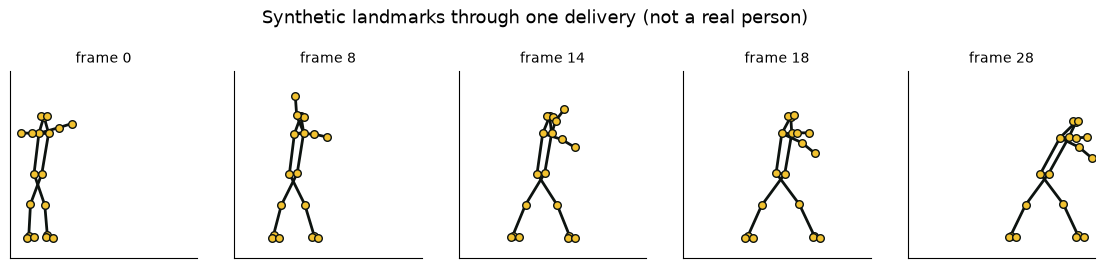

In [5]:
def draw_figure(ax, lm, title=""):
    for a, b in pose.SKELETON:
        if lm[a, 3] > 0.5 and lm[b, 3] > 0.5:
            ax.plot([lm[a, 0], lm[b, 0]], [lm[a, 1], lm[b, 1]], color=INK, lw=2)
    seen = lm[:, 3] > 0.5
    ax.scatter(lm[seen, 0], lm[seen, 1], color=YELLOW, edgecolor=INK, zorder=3, s=30)
    ax.set_xlim(0, 1); ax.set_ylim(1, 0); ax.set_aspect("equal"); ax.set_xticks([]); ax.set_yticks([]); ax.grid(False)
    ax.set_title(title, fontsize=10)

fig, axes = plt.subplots(1, 5, figsize=(14, 3.2))
for ax, f in zip(axes, [0, 8, 14, 18, 28]):
    draw_figure(ax, delivery_a[f], f"frame {f}")
fig.suptitle("Synthetic landmarks through one delivery (not a real person)"); plt.show()

## 5. Measurements for each frame

`pose.frame_metrics` turns one frame's landmarks into indicators:

| Indicator | Meaning |
|---|---|
| elbow / knee angle | interior joint angle in degrees |
| trunk lean | tilt of the hip-to-shoulder line from vertical |
| shoulder tilt | tilt of the shoulder line from level |
| head offset | how far the head is sideways from the middle of the feet, in torso lengths (a balance indicator) |
| stride ratio | distance between the feet, in torso lengths |

A landmark with visibility below 0.5 is treated as missing, and any indicator that needs it is left empty.

In [6]:
def measure(frames, fps=30.0):
    return [{"frame": i, "t": i / fps, "metrics": pose.frame_metrics(lm)} for i, lm in enumerate(frames)]

seq_a = measure(delivery_a)
table = pd.DataFrame([{"frame": f["frame"], **{k: f["metrics"][k] for k in
                      ("trunk_lean", "shoulder_tilt", "head_offset", "stride_ratio", "left_knee_angle", "right_elbow_angle")}} for f in seq_a])
table.round(2).iloc[::5]

,frame,trunk_lean,shoulder_tilt,head_offset,stride_ratio,left_knee_angle,right_elbow_angle
0,0,8.21,-0.63,0.14,0.45,165.89,177.87
5,5,8.55,-2.89,0.16,0.78,167.80,167.09
10,10,8.71,-4.21,0.18,1.11,170.65,164.13
15,15,8.54,3.34,0.22,1.42,168.51,165.77
20,20,12.13,-8.27,0.34,1.63,170.86,179.09
25,25,22.94,-2.26,0.58,1.64,171.63,173.17


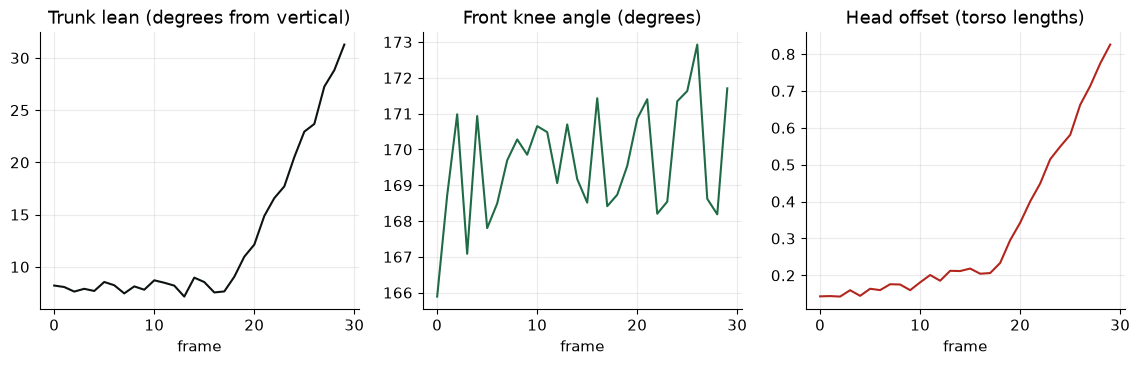

In [7]:
fig, axes = plt.subplots(1, 3, figsize=(14, 3.6))
axes[0].plot(table["frame"], table["trunk_lean"], color=INK); axes[0].set_title("Trunk lean (degrees from vertical)")
axes[1].plot(table["frame"], table["left_knee_angle"], color=GREEN); axes[1].set_title("Front knee angle (degrees)")
axes[2].plot(table["frame"], table["head_offset"], color=RED); axes[2].set_title("Head offset (torso lengths)")
for ax in axes: ax.set_xlabel("frame")
plt.show()

## 6. Summarising the delivery

`pose.summarise_sequence` finds the release frame (the frame where the bowling wrist is highest), reads the indicators at that moment, measures how steady the run-up speed was (coefficient of variation = standard deviation / mean of the hip's speed), and writes coaching observations. Every observation states the measurement that triggered it.

In [8]:
summary_a = pose.summarise_sequence(seq_a, mode="bowling")
print("Status:", summary_a["status"], "| bowling arm:", summary_a["indicators"]["bowling_arm"], "| release frame:", summary_a["key_frame"])
for o in summary_a["observations"]:
    print(f"- [{o['kind']}] {o['text']}\n    measured: {o['evidence']}")
print("\n" + summary_a["disclaimer"])

Status: ok | bowling arm: right | release frame: 9
- [strength] Head stays over the base of support at release.
    measured: Head offset +0.16 torso lengths from the midpoint of the feet.
- [strength] Front leg is braced (close to straight) at release.
    measured: Front knee angle 170 deg at the release frame.
- [strength] Run-up speed is steady into the crease.
    measured: Coefficient of variation of hip speed 0.05 over 10 frames (< 0.35).
- [note] Delivery stride length recorded for comparison between deliveries.
    measured: Feet 1.02 torso lengths apart at release.

Angles are 2-D measurements from one camera and depend on where the camera stood. They are coaching observations only. They do not diagnose injury risk, medical safety, or whether a bowling action is legal.


## 7. Comparing two deliveries

Delivery B is generated with a flexed front knee, more trunk lean, a head that falls away, and an uneven run-up.

In [9]:
delivery_b = synthetic_delivery(lean=24, front_knee=132, head_drift=0.14, speed_wobble=3.0, seed=2)
summary_b = pose.summarise_sequence(measure(delivery_b), mode="bowling")
comparison = pose.compare_analyses(summary_a, summary_b)
pd.DataFrame(comparison["rows"]).round(2)

,metric,a,b,difference
0,release.trunk_lean,7.81,24.54,16.74
1,release.shoulder_tilt,-5.74,-2.47,3.27
2,release.head_offset,0.16,0.73,0.57
3,release.stride_ratio,1.02,1.04,0.01
4,release.right_elbow_angle,167.01,168.32,1.31
5,release.left_knee_angle,169.85,147.00,-22.85
6,release.left_shoulder_angle,91.26,111.20,19.94
7,release.bowling_elbow_angle,167.01,168.32,1.31
8,release.front_knee_angle,169.85,147.00,-22.85
9,release.front_arm_angle,91.26,111.20,19.94


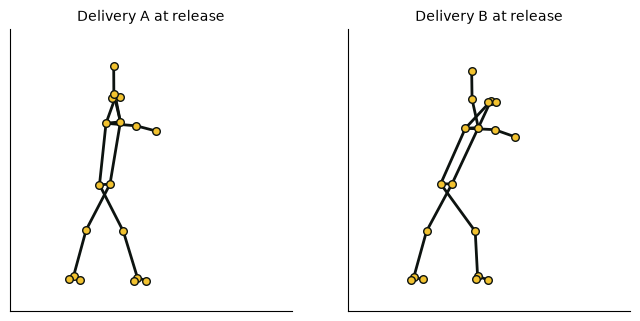

Observations for delivery B:
- [focus] Head is well outside the base of support at release; work on keeping the head over the front foot.  (Head offset +0.73 torso lengths from the midpoint of the feet (|offset| > 0.45).)
- [focus] Run-up speed varies a lot frame to frame; rhythm drills may help.  (Coefficient of variation of hip speed 0.69 over 10 frames (>= 0.35).)
- [note] Delivery stride length recorded for comparison between deliveries.  (Feet 1.04 torso lengths apart at release.)

Differences are meaningful only if both clips were filmed from the same camera position. Differences of a few degrees are within pose-estimation error.


In [10]:
fig, axes = plt.subplots(1, 2, figsize=(8, 4))
draw_figure(axes[0], delivery_a[summary_a["key_frame"]], "Delivery A at release")
draw_figure(axes[1], delivery_b[summary_b["key_frame"]], "Delivery B at release")
plt.show()
print("Observations for delivery B:")
for o in summary_b["observations"]:
    print(f"- [{o['kind']}] {o['text']}  ({o['evidence']})")
print("\n" + comparison["note"])

## 8. Too little to measure

If a person is found in fewer than five frames, nothing is reported.

In [11]:
short = pose.summarise_sequence(measure(delivery_a[:3]), mode="bowling")
print(short["status"], "-", short["reason"])

insufficient - A person was found in only 3 frame(s); at least 5 are needed. Film the whole body, side-on, in good light, with one person in shot.


## 9. The video pipeline

This section runs on a real file. With no video supplied it writes a tiny synthetic clip (a moving dot, no person) to show frame extraction working and to show what happens when MediaPipe finds nobody.

No video supplied: using a synthetic clip with no person in it.
Video: {'fps': 120.0, 'fps_assumed': False, 'frame_count': 46, 'width': 640, 'height': 360, 'duration_s': 0.38333333333333336}


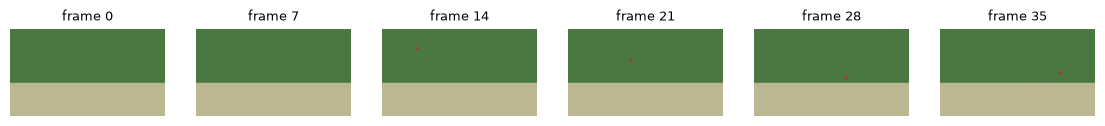

In [12]:
import tempfile, os
path = VIDEO_PATH
if path is None:
    path = os.path.join(tempfile.mkdtemp(), "synthetic_no_person.mp4")
    tracking.write_synthetic_ball_video(path)
    print("No video supplied: using a synthetic clip with no person in it.")

cap, info = tracking.open_video(path); cap.release()
print("Video:", info)
frames = list(tracking.extract_frames(path, every=max(1, info["frame_count"] // 6), max_frames=6))
fig, axes = plt.subplots(1, len(frames), figsize=(14, 2.6))
for ax, (idx, t, img) in zip(axes, frames):
    ax.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB)); ax.set_title(f"frame {idx}", fontsize=9); ax.axis("off")
plt.show()

In [13]:
# Full analysis: MediaPipe on the sampled frames, then the same summary as above.
try:
    result = pose.analyse_video(path, mode=MODE)
    print("Status:", result["status"], "| frames with a person:", result.get("frames_with_pose", 0), "of", result["frames_processed"])
    if result["status"] != "ok":
        print("Reason:", result["reason"])
    else:
        for o in result["observations"]:
            print(f"- [{o['kind']}] {o['text']}  ({o['evidence']})")
        import base64, io
        from PIL import Image
        shots = result["annotated_frames"][:4]
        fig, axes = plt.subplots(1, len(shots), figsize=(14, 4))
        for ax, s in zip(np.atleast_1d(axes), shots):
            ax.imshow(Image.open(io.BytesIO(base64.b64decode(s["image"].split(",")[1])))); ax.axis("off")
            ax.set_title(f"frame {s['frame']}" + (" (key frame)" if s["key"] else ""))
        plt.show()
except pose.PoseError as e:
    print("Pose estimation is not available here:", e)
except tracking.VideoError as e:
    print("The video could not be read:", e)

I0000 00:00:1794449567.473988 1388699 init-domain.cc:133] Fiber init: default domain = pthread, concurrency = 8, prefix = pthread-default
INFO: Created TensorFlow Lite XNNPACK delegate for CPU.
W0000 00:00:1794449567.566924 1388701 inference_feedback_manager.cc:121] Feedback manager requires a model with a single signature inference. Disabling support for feedback tensors.
W0000 00:00:1794449567.590921 1388701 inference_feedback_manager.cc:121] Feedback manager requires a model with a single signature inference. Disabling support for feedback tensors.


Status: insufficient | frames with a person: 0 of 46
Reason: A person was found in only 0 frame(s); at least 5 are needed. Film the whole body, side-on, in good light, with one person in shot.


## Summary

### Key findings
- Joint angles come from the dot-product formula; the hand version and `pitchvision.pose.angle_between` agree exactly.
- On the synthetic figures, the analysis picks out the release frame and reports the differences that were built into delivery B (flexed front knee, more trunk lean, head outside the base, uneven run-up).
- With too few frames, or no person in the clip, the result is 'insufficient' rather than a guess.

### Interpretation
The indicators are best used to compare one bowler's deliveries with each other, filmed from the same position. Thresholds in the observations (for example a front knee below 140 degrees) are coaching rules of thumb, not standards.

### Limitations
- 2-D angles from one camera change with camera position and lens.
- Fast arm movement blurs at 30 fps; landmarks on the bowling arm are least reliable near release.
- Differences of a few degrees are within the model's error.
- No medical, injury-risk or legality conclusion can be drawn.
- The demonstration above uses synthetic landmarks; the real-video path was exercised only on a clip with no person in it.

### How this notebook connects to the application
The Bowling Lab (Action analyzer), Batting Lab (Action analyzer) and Fielding Lab (Catching technique) upload a clip to `POST /api/video/pose`, which calls `pitchvision.pose.analyse_video`: the same `frame_metrics`, `summarise_sequence` and `compare_analyses` used here.